<a href="https://colab.research.google.com/github/zeusandatlasgh/zeusandatlas/blob/hw00/CPE486586_HigginbothamArwen_HW_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Problem 8
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Raw CSV link (on GitHub, click the file, then the "Raw" button):
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Diabetes/diabetes.csv"
df = pd.read_csv(url)

print(df.shape)                     # (768, 9)
print(df["Outcome"].value_counts()) # 0: 500, 1: 268

X = df.drop(columns="Outcome")      # 8 features
y = df["Outcome"]                   # labels (used for coloring only)

(768, 9)
Outcome
0    500
1    268
Name: count, dtype: int64


In [2]:
X_scaled = StandardScaler().fit_transform(X)

In [3]:
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)   # shape (768, 2)

print(pca2.explained_variance_ratio_)        # each component's share
print(pca2.explained_variance_ratio_.sum())  # total

[0.26179749 0.21640127]
0.47819876073856576


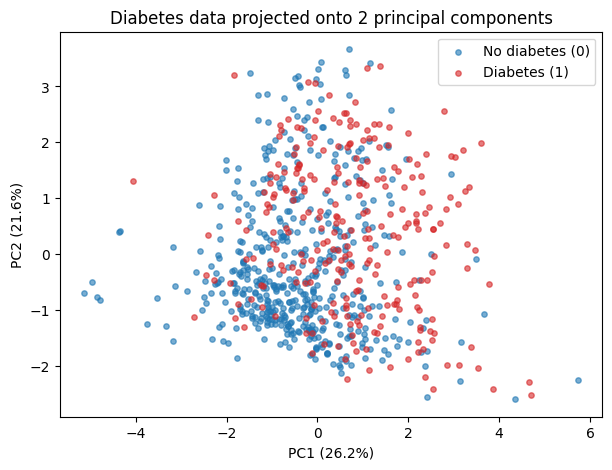

In [4]:
plt.figure(figsize=(7, 5))
for label, color, name in [(0, "tab:blue", "No diabetes (0)"),
                           (1, "tab:red",  "Diabetes (1)")]:
    mask = (y == label)
    plt.scatter(X_pca2[mask, 0], X_pca2[mask, 1],
                c=color, label=name, alpha=0.6, s=15)
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})")
plt.title("Diabetes data projected onto 2 principal components")
plt.legend()
plt.show()

In [5]:
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

for i, r in enumerate(pca3.explained_variance_ratio_, 1):
    print(f"PC{i}: {r:.2%}")
print("Total:", f"{pca3.explained_variance_ratio_.sum():.2%}")

# Optional but very useful: what each component is made of
loadings = pd.DataFrame(pca3.components_.T, index=X.columns,
                        columns=["PC1", "PC2", "PC3"])
print(loadings.round(3))

PC1: 26.18%
PC2: 21.64%
PC3: 12.87%
Total: 60.69%
                            PC1    PC2    PC3
Pregnancies               0.128  0.594  0.013
Glucose                   0.393  0.174 -0.468
BloodPressure             0.360  0.184  0.535
SkinThickness             0.440 -0.332  0.238
Insulin                   0.435 -0.251 -0.337
BMI                       0.452 -0.101  0.362
DiabetesPedigreeFunction  0.271 -0.122 -0.433
Age                       0.198  0.621 -0.075


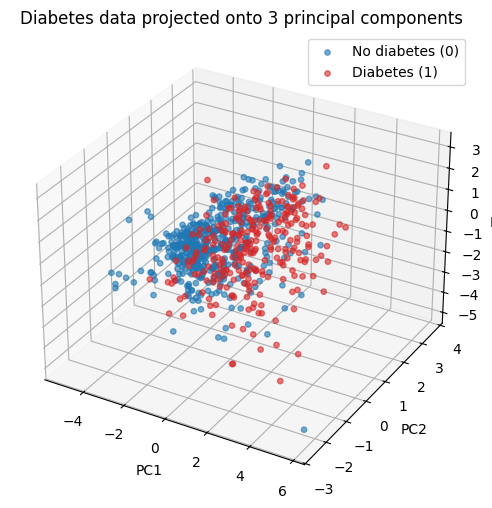

In [6]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
for label, color, name in [(0, "tab:blue", "No diabetes (0)"),
                           (1, "tab:red",  "Diabetes (1)")]:
    mask = (y == label)
    ax.scatter(X_pca3[mask, 0], X_pca3[mask, 1], X_pca3[mask, 2],
               c=color, label=name, alpha=0.6, s=15)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("Diabetes data projected onto 3 principal components")
ax.legend()
plt.show()

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
for name, Z in [("2 PCs", X_pca2), ("3 PCs", X_pca3), ("All 8 features", X_scaled)]:
    print(name, cross_val_score(LogisticRegression(), Z, y, cv=5).mean().round(3))

2 PCs 0.724
3 PCs 0.73
All 8 features 0.771


In [14]:
#Problem 9
from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

def plot_decision_boundary(model, X_data, y_data, title):
    # Grid covering the data, with a small margin
    x_min, x_max = X_data[:, 0].min() - 0.5, X_data[:, 0].max() + 0.5
    y_min, y_max = X_data[:, 1].min() - 0.5, X_data[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                         np.linspace(y_min, y_max, 400))
    # Score every grid point, then reshape back into a grid
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.decision_function(grid).reshape(xx.shape)
    # Shaded regions + boundary line (Z = 0) + data points
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z > 0, alpha=0.25, cmap="coolwarm")
    plt.contour(xx, yy, Z, levels=[0], colors="k")
    plt.scatter(X_data[:, 0], X_data[:, 1], c=y_data, cmap="coolwarm",
                edgecolors="k", s=20)
    plt.title(title)
    plt.xlabel("x1"); plt.ylabel("x2")
    plt.show()

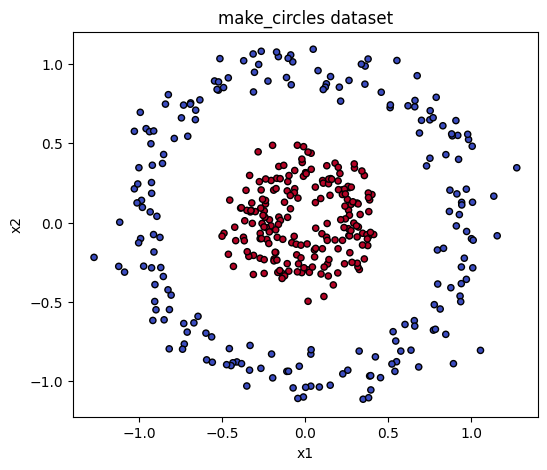

In [9]:
X_circ, y_circ = make_circles(n_samples=400, noise=0.1, factor=0.3, random_state=1)

plt.figure(figsize=(6, 5))
plt.scatter(X_circ[:, 0], X_circ[:, 1], c=y_circ, cmap="coolwarm",
            edgecolors="k", s=20)
plt.title("make_circles dataset")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()

Linear SVM accuracy: 0.6725
Support vectors: 398


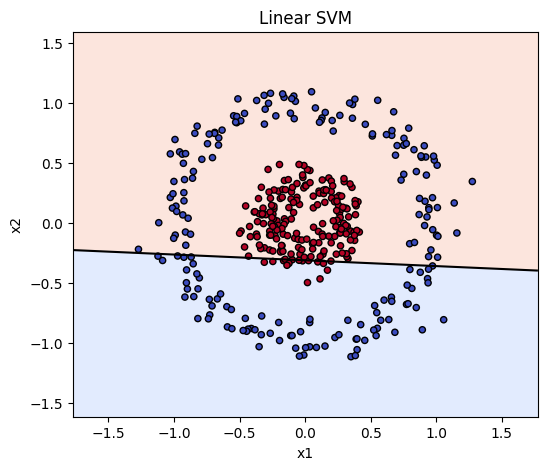

In [10]:
svm_linear = SVC(kernel="linear")
svm_linear.fit(X_circ, y_circ)
print("Linear SVM accuracy:", svm_linear.score(X_circ, y_circ))
print("Support vectors:", svm_linear.n_support_.sum())
plot_decision_boundary(svm_linear, X_circ, y_circ, "Linear SVM")

RBF (gamma=1.0) accuracy: 1.0
Support vectors: 32


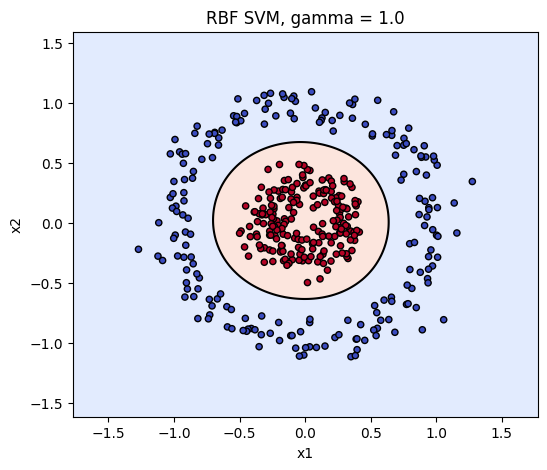

In [11]:
svm_rbf = SVC(kernel="rbf", gamma=1.0)
svm_rbf.fit(X_circ, y_circ)
print("RBF (gamma=1.0) accuracy:", svm_rbf.score(X_circ, y_circ))
print("Support vectors:", svm_rbf.n_support_.sum())
plot_decision_boundary(svm_rbf, X_circ, y_circ, "RBF SVM, gamma = 1.0")

gamma=0.1: accuracy=1.000, support vectors=290


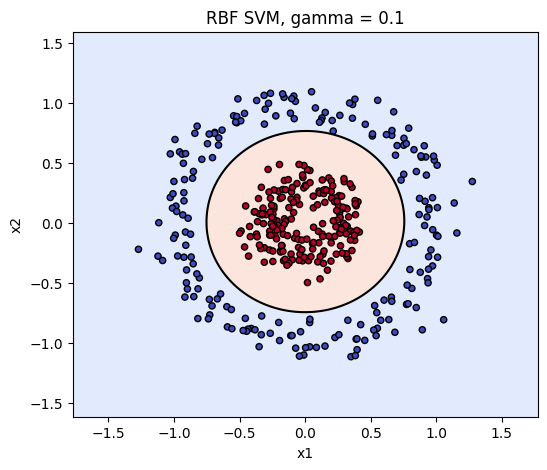

gamma=10: accuracy=1.000, support vectors=52


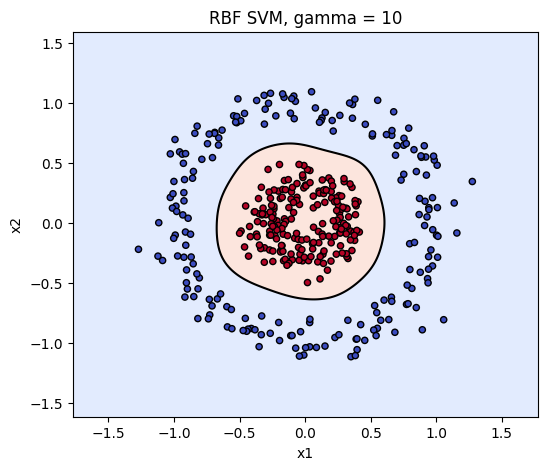

In [12]:
for gamma_val in [0.1, 10]:
    svm_gamma = SVC(kernel="rbf", gamma=gamma_val)
    svm_gamma.fit(X_circ, y_circ)
    print(f"gamma={gamma_val}: accuracy={svm_gamma.score(X_circ, y_circ):.3f}, "
          f"support vectors={svm_gamma.n_support_.sum()}")
    plot_decision_boundary(svm_gamma, X_circ, y_circ, f"RBF SVM, gamma = {gamma_val}")

In [13]:
X_noisy, y_noisy = make_circles(n_samples=400, noise=0.25, factor=0.3, random_state=1)
X_noisy_tr, X_noisy_te, y_noisy_tr, y_noisy_te = train_test_split(
    X_noisy, y_noisy, test_size=0.3, random_state=42, stratify=y_noisy)

for gamma_val in [0.01, 1, 1000]:
    svm_noisy = SVC(kernel="rbf", gamma=gamma_val).fit(X_noisy_tr, y_noisy_tr)
    print(f"gamma={gamma_val}: train={svm_noisy.score(X_noisy_tr, y_noisy_tr):.3f}, "
          f"test={svm_noisy.score(X_noisy_te, y_noisy_te):.3f}")

gamma=0.01: train=0.668, test=0.650
gamma=1: train=0.932, test=0.883
gamma=1000: train=0.996, test=0.792


In [15]:
#Problem 10
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, v_measure_score,
                             silhouette_score, calinski_harabasz_score)
import numpy as np
import matplotlib.pyplot as plt

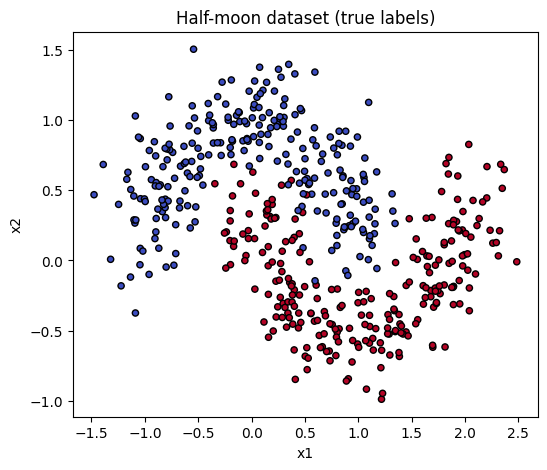

In [16]:
X_moon, y_moon = make_moons(n_samples=500, noise=0.2, random_state=42)

plt.figure(figsize=(6, 5))
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap="coolwarm",
            edgecolors="k", s=20)
plt.title("Half-moon dataset (true labels)")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()

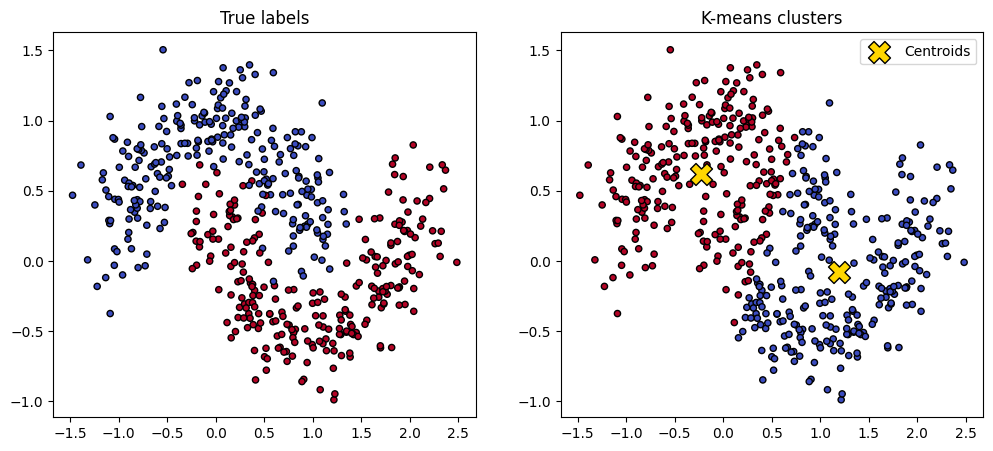

In [17]:
kmeans_moon = KMeans(n_clusters=2, n_init=10, random_state=42)
labels_moon = kmeans_moon.fit_predict(X_moon)   # cluster ID (0 or 1) per point

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, cmap="coolwarm",
                edgecolors="k", s=20)
axes[0].set_title("True labels")
axes[1].scatter(X_moon[:, 0], X_moon[:, 1], c=labels_moon, cmap="coolwarm",
                edgecolors="k", s=20)
centers_moon = kmeans_moon.cluster_centers_
axes[1].scatter(centers_moon[:, 0], centers_moon[:, 1], c="gold", marker="X",
                s=250, edgecolors="k", label="Centroids")
axes[1].set_title("K-means clusters")
axes[1].legend()
plt.show()

In [18]:
ari_moon = adjusted_rand_score(y_moon, labels_moon)
vmeasure_moon = v_measure_score(y_moon, labels_moon)
silhouette_moon = silhouette_score(X_moon, labels_moon)
ch_moon = calinski_harabasz_score(X_moon, labels_moon)

print(f"Adjusted Rand Index:     {ari_moon:.4f}")
print(f"V-measure:               {vmeasure_moon:.4f}")
print(f"Silhouette Score:        {silhouette_moon:.4f}")
print(f"Calinski-Harabasz Index: {ch_moon:.2f}")

Adjusted Rand Index:     0.2773
V-measure:               0.2122
Silhouette Score:        0.4689
Calinski-Harabasz Index: 664.08


In [19]:
print("Silhouette (true labels):", silhouette_score(X_moon, y_moon))          # 0.3050
print("Calinski-Harabasz (true labels):", calinski_harabasz_score(X_moon, y_moon))  # 303.46

Silhouette (true labels): 0.30503792987091827
Calinski-Harabasz (true labels): 303.4593706519733


In [20]:
#Problem 11
!pip install -q onnx onnxruntime onnxscript

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import onnxruntime as ort
import joblib

In [22]:
class TorchNet(nn.Module):

    # ---- Part 2 + Bonus: build the network ----
    def __init__(self, input_dim, output_dim, hidden1=4, hidden2=3):
        super().__init__()                      # required for every nn.Module
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden1),      # input  -> hidden layer 1 (4 neurons)
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),        # hidden 1 -> hidden layer 2 (3 neurons)
            nn.ReLU(),
            nn.Linear(hidden2, output_dim)      # hidden 2 -> output
        )
        self.input_dim = input_dim
        self.scaler = StandardScaler()
        self.loss_history = []

    def forward(self, x):
        return self.layers(x)

    # ---- Part 1: standardization ----
    def standardize(self, X, fit=False):
        # fit=True only on training data; afterward just transform
        X_scaled = self.scaler.fit_transform(X) if fit else self.scaler.transform(X)
        return torch.tensor(X_scaled, dtype=torch.float32)

    # ---- Part 3: training ----
    def fit(self, X_train, y_train, epochs=1000, lr=0.01):
        X_t = self.standardize(X_train, fit=True)
        y_t = torch.tensor(np.asarray(y_train), dtype=torch.float32).reshape(-1, 1)

        loss_fn = nn.BCEWithLogitsLoss()                      # binary classification loss
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        self.loss_history = []
        self.train()                                          # put model in training mode

        for epoch in range(epochs):
            optimizer.zero_grad()            # 1. clear old gradients
            outputs = self(X_t)              # 2. forward pass
            loss = loss_fn(outputs, y_t)     # 3. compute loss
            loss.backward()                  # 4. backpropagation
            optimizer.step()                 # 5. update weights
            self.loss_history.append(loss.item())
            if (epoch + 1) % 100 == 0:
                print(f"Epoch {epoch+1:4d}/{epochs}  loss = {loss.item():.4f}")

    # ---- Part 4: loss plot ----
    def plot_loss(self):
        plt.figure(figsize=(7, 4))
        plt.plot(range(1, len(self.loss_history) + 1), self.loss_history)
        plt.xlabel("Epoch"); plt.ylabel("BCE loss")
        plt.title("Training loss vs. epochs")
        plt.grid(alpha=0.3)
        plt.show()

    # Helper: predict with the in-memory PyTorch model
    def predict(self, X):
        self.eval()
        with torch.no_grad():
            probs = torch.sigmoid(self(self.standardize(X)))
        return (probs >= 0.5).int().numpy().ravel()

    # ---- Part 5: save to ONNX ----
    def save_onnx(self, onnx_path, scaler_path):
        self.eval()
        dummy_input = torch.randn(1, self.input_dim)    # example input that defines the shape
        torch.onnx.export(self, dummy_input, onnx_path,
                          input_names=["features"], output_names=["logit"],
                          external_data=False)          # keep everything in one file
        joblib.dump(self.scaler, scaler_path)           # the scaler must be saved too!
        print(f"Saved model to {onnx_path} and scaler to {scaler_path}")

    # ---- Part 6: load the saved model and predict ----
    @staticmethod
    def load_and_predict(onnx_path, scaler_path, X):
        session = ort.InferenceSession(onnx_path)
        scaler = joblib.load(scaler_path)
        X_scaled = scaler.transform(X).astype(np.float32)   # ONNX expects float32
        logits = session.run(None, {"features": X_scaled})[0]
        probs = 1 / (1 + np.exp(-logits))                   # sigmoid
        return probs.ravel(), (probs >= 0.5).astype(int).ravel()

In [23]:
torch.manual_seed(42)   # makes weight initialization reproducible

df_nn = pd.read_csv("https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Diabetes/diabetes.csv")
X_nn = df_nn.drop(columns="Outcome")
y_nn = df_nn["Outcome"]

X_nn_train, X_nn_test, y_nn_train, y_nn_test = train_test_split(
    X_nn, y_nn, test_size=0.2, random_state=42, stratify=y_nn)

In [24]:
net = TorchNet(input_dim=X_nn.shape[1], output_dim=1)   # 8 inputs, 1 output (the bonus)
print(net)
net.fit(X_nn_train, y_nn_train, epochs=1000, lr=0.01)

TorchNet(
  (layers): Sequential(
    (0): Linear(in_features=8, out_features=4, bias=True)
    (1): ReLU()
    (2): Linear(in_features=4, out_features=3, bias=True)
    (3): ReLU()
    (4): Linear(in_features=3, out_features=1, bias=True)
  )
)
Epoch  100/1000  loss = 0.4301
Epoch  200/1000  loss = 0.4122
Epoch  300/1000  loss = 0.4072
Epoch  400/1000  loss = 0.4019
Epoch  500/1000  loss = 0.3987
Epoch  600/1000  loss = 0.3970
Epoch  700/1000  loss = 0.3963
Epoch  800/1000  loss = 0.3960
Epoch  900/1000  loss = 0.3959
Epoch 1000/1000  loss = 0.3958


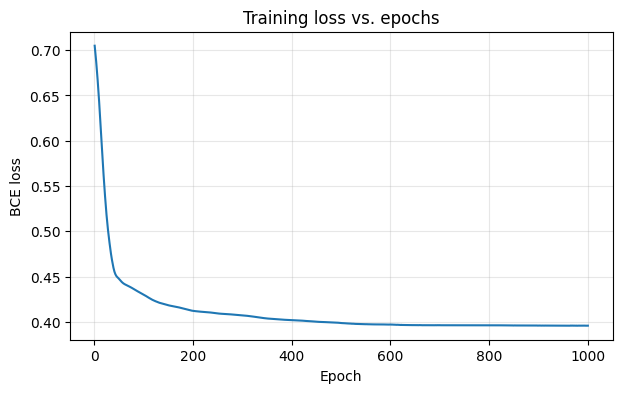

Train accuracy: 0.819   Test accuracy: 0.721


In [25]:
net.plot_loss()

train_acc_nn = (net.predict(X_nn_train) == y_nn_train.values).mean()
test_acc_nn = (net.predict(X_nn_test) == y_nn_test.values).mean()
print(f"Train accuracy: {train_acc_nn:.3f}   Test accuracy: {test_acc_nn:.3f}")

In [26]:
net.save_onnx("diabetes_net.onnx", "diabetes_scaler.pkl")

[torch.onnx] Obtain model graph for `TorchNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `TorchNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Saved model to diabetes_net.onnx and scaler to diabetes_scaler.pkl


In [27]:
new_patient_nn = pd.DataFrame(
    [[7, 149, 73, 94, 94, 32, 0.672, 45]],
    columns=X_nn.columns)    # same column names and order as training

prob_nn, pred_nn = TorchNet.load_and_predict("diabetes_net.onnx", "diabetes_scaler.pkl",
                                             new_patient_nn)
print(f"Probability of diabetes: {prob_nn[0]:.3f}")
print(f"Predicted Outcome: {pred_nn[0]}")

Probability of diabetes: 0.967
Predicted Outcome: 1
